# 02 – Modelos de IA do Refúgio

1. **Visão computacional (CNN):** classificar o uso do solo em imagens de satélite para medir a área construída de cada setor.
2. **Índice de risco + clusterização (K-Means):** combinar perigo, exposição e vulnerabilidade e descrever perfis de setores.
3. **Sistemas de recomendação:** refúgio climático para o cidadão e prioridade de plantio para o gestor.

Os modelos são treinados e aplicados pelos scripts de `src/ml/`. Este caderno lê os resultados e as métricas salvas, para que possa ser executado em poucos segundos.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd, numpy as np, geopandas as gpd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config as C
from src.analise import figuras
pd.set_option("display.precision", 3)
setores = gpd.read_file(C.PROCESSED / "setores_santa_maria.gpkg")
m_cnn = json.loads((C.MODELOS / "metricas_cnn.json").read_text(encoding="utf-8"))
m_clu = json.loads((C.MODELOS / "metricas_clusters.json").read_text(encoding="utf-8"))
m_rec = json.loads((C.MODELOS / "metricas_recomendacao.json").read_text(encoding="utf-8"))

## 1. CNN de uso do solo

**Por quê:** o NDVI mede vegetação, mas não diferencia um telhado de um campo seco. Uma CNN reconhece *padrões espaciais*, como quadras, ruas e telhados, e estima quanto de cada setor é área construída, um fator que aumenta o calor.

**Dados de treino:** EuroSAT RGB (27.000 recortes Sentinel-2 de 64×64 px, 10 classes). Divisão estratificada: 70% treino, 15% validação, 15% teste. A normalização é calculada só no treino, para evitar vazamento.

**Abordagens comparadas:**
| Modelo | Ideia |
|---|---|
| Random Forest em histogramas de cor | Baseline clássico, sem rede neural |
| CNN pequena treinada do zero | 3 blocos convolucionais, cerca de 290 mil parâmetros |
| ResNet-18 com *transfer learning* | Rede pré-treinada no ImageNet com ajuste fino |

In [2]:
linhas = []
for k, nome in [("baseline_rf_histograma","Random Forest (histograma)"),("cnn_pequena","CNN pequena"),("resnet18_transfer","ResNet-18 transfer")]:
    r = m_cnn[k]
    linhas.append({"modelo": nome, "acurácia validação": r["acuracia_validacao"], "acurácia teste": r["acuracia_teste"],
                   "F1-macro teste": r["f1_macro_teste"], "parâmetros": r.get("parametros", "-"), "tempo (s)": round(r["tempo_s"])})
display(pd.DataFrame(linhas))
print("Modelo escolhido pela validação:", m_cnn["modelo_escolhido"])
print(f"Acurácia na tarefa do projeto (construído x vegetação x água): {m_cnn['acuracia_grupos_construido_vegetacao_agua']:.3f}")

,modelo,acurácia validação,acurácia teste,F1-macro teste,parâmetros,tempo (s)
0,Random Forest (histograma),0.800,0.819,0.809,-,34
1,CNN pequena,0.947,0.954,0.953,289194,1699
2,ResNet-18 transfer,0.978,0.980,0.980,11181642,918


Modelo escolhido pela validação: resnet18_transfer
Acurácia na tarefa do projeto (construído x vegetação x água): 0.995


salvo docs/img/cnn_comparacao_modelos.png


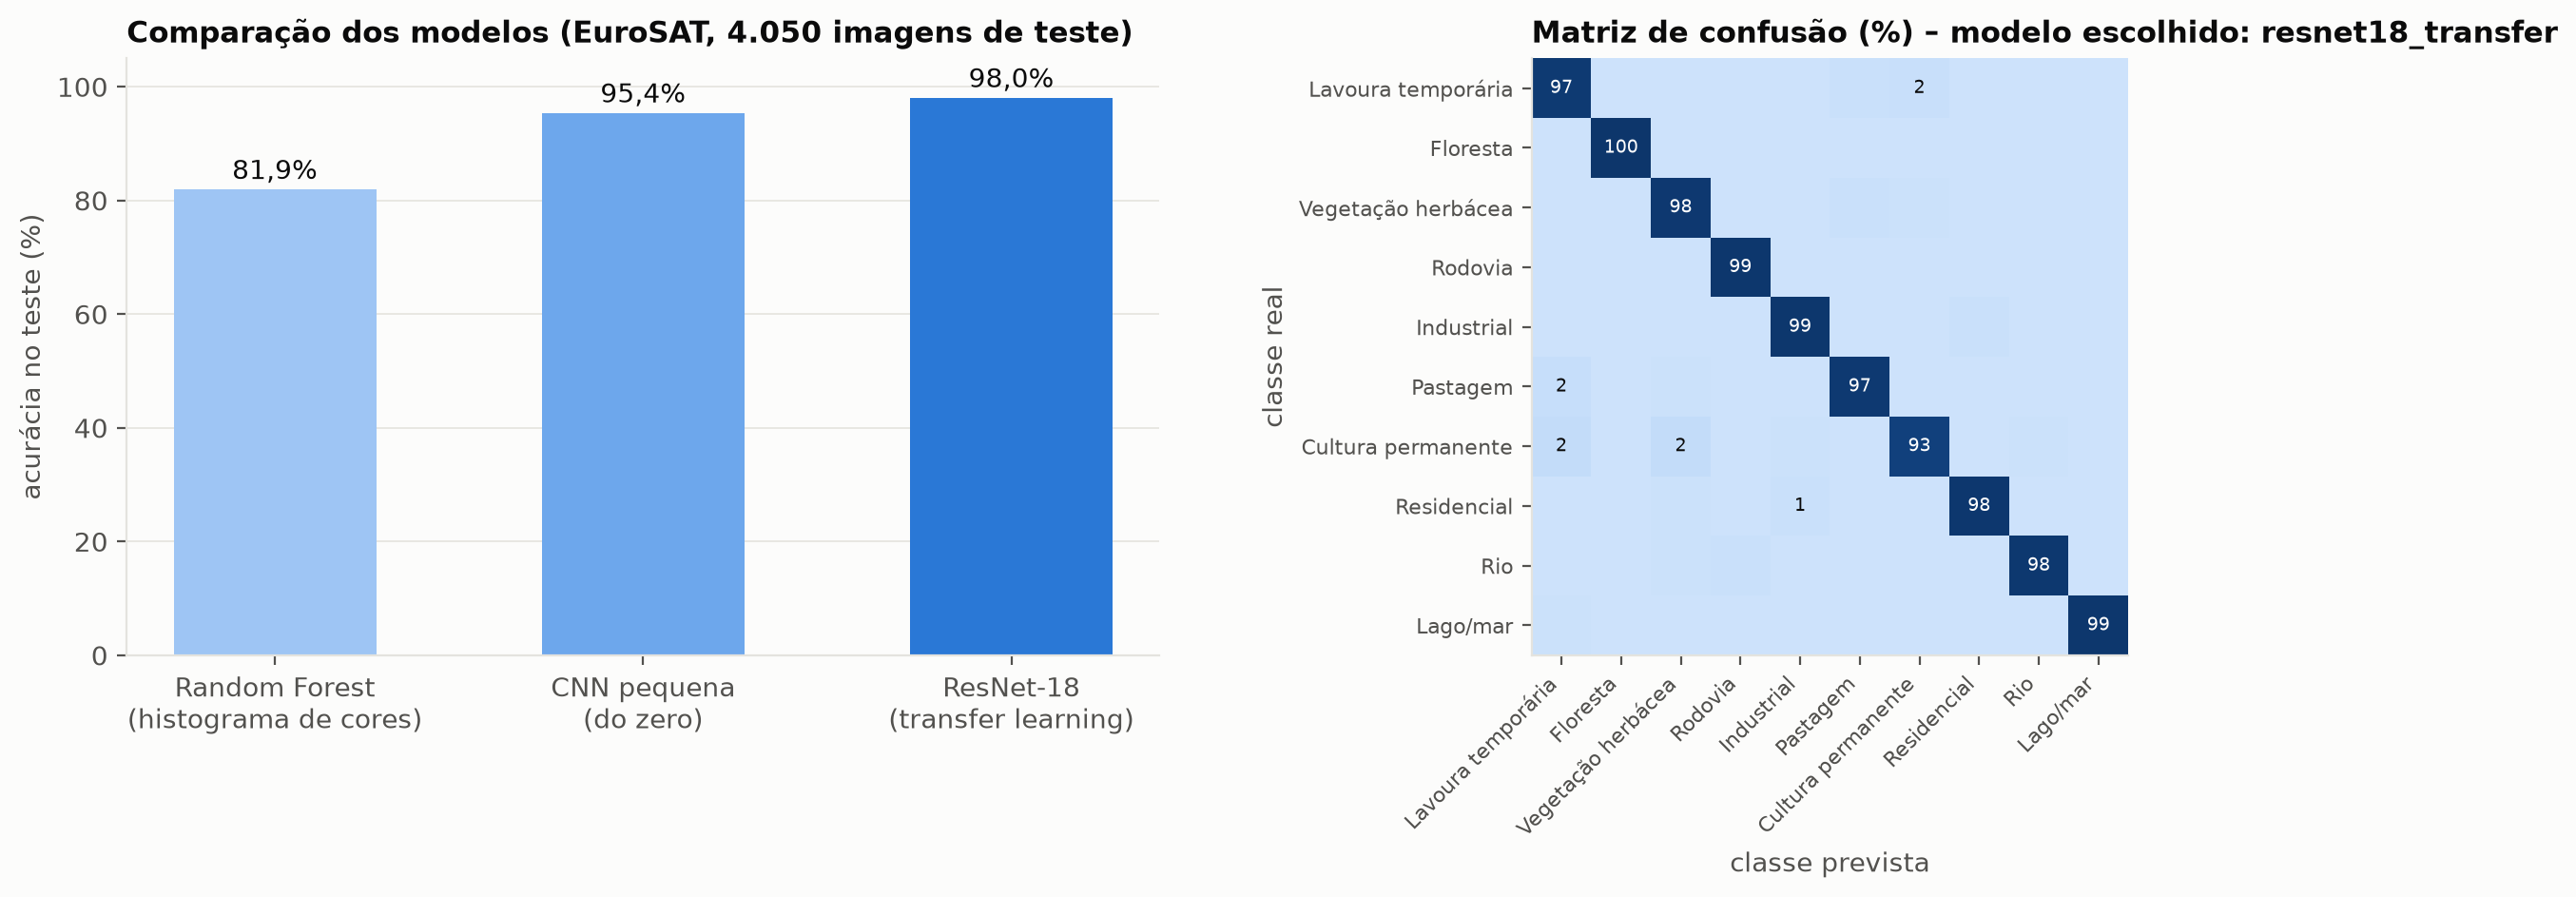

In [3]:
figuras.modelos_cnn()
Image(C.DOCS_IMG / "cnn_comparacao_modelos.png")

In [4]:
pd.DataFrame(m_cnn["relatorio_por_classe"]).T.iloc[:10][["precision","recall","f1-score","support"]]

,precision,recall,f1-score,support
Lavoura temporária,0.965,0.971,0.968,450.0
Floresta,0.993,0.998,0.996,450.0
Vegetação herbácea,0.965,0.980,0.972,450.0
Rodovia,0.984,0.992,0.988,375.0
Industrial,0.979,0.992,0.985,375.0
Pastagem,0.967,0.973,0.970,300.0
Cultura permanente,0.972,0.933,0.952,375.0
Residencial,0.991,0.984,0.988,450.0
Rio,0.987,0.984,0.985,375.0
Lago/mar,0.998,0.991,0.994,450.0


### 1.1 Aplicação em Santa Maria e validação externa

A CNN percorre uma imagem Sentinel-2 real da cidade com uma janela deslizante (64×64 px, passo de 16 px) e gera um mapa de probabilidade de área construída. Para **validar sem rótulos locais**, comparamos a fração construída de cada setor com duas medidas que a CNN **nunca viu**: o NDVI e a temperatura de superfície do Landsat.

{
 "cena": {
  "id": "S2B_MSIL2A_20250203T133839_R124_T22JBN_20250203T184800",
  "data": "2025-02-03",
  "nuvens_%": 0.000741
 },
 "validacao_setores": {
  "construida_x_ndvi": -0.7093089699349411,
  "construida_x_lst": 0.7237715209664037,
  "spearman_construida_x_lst": 0.48690616276823173
 },
 "n_setores": 406
}


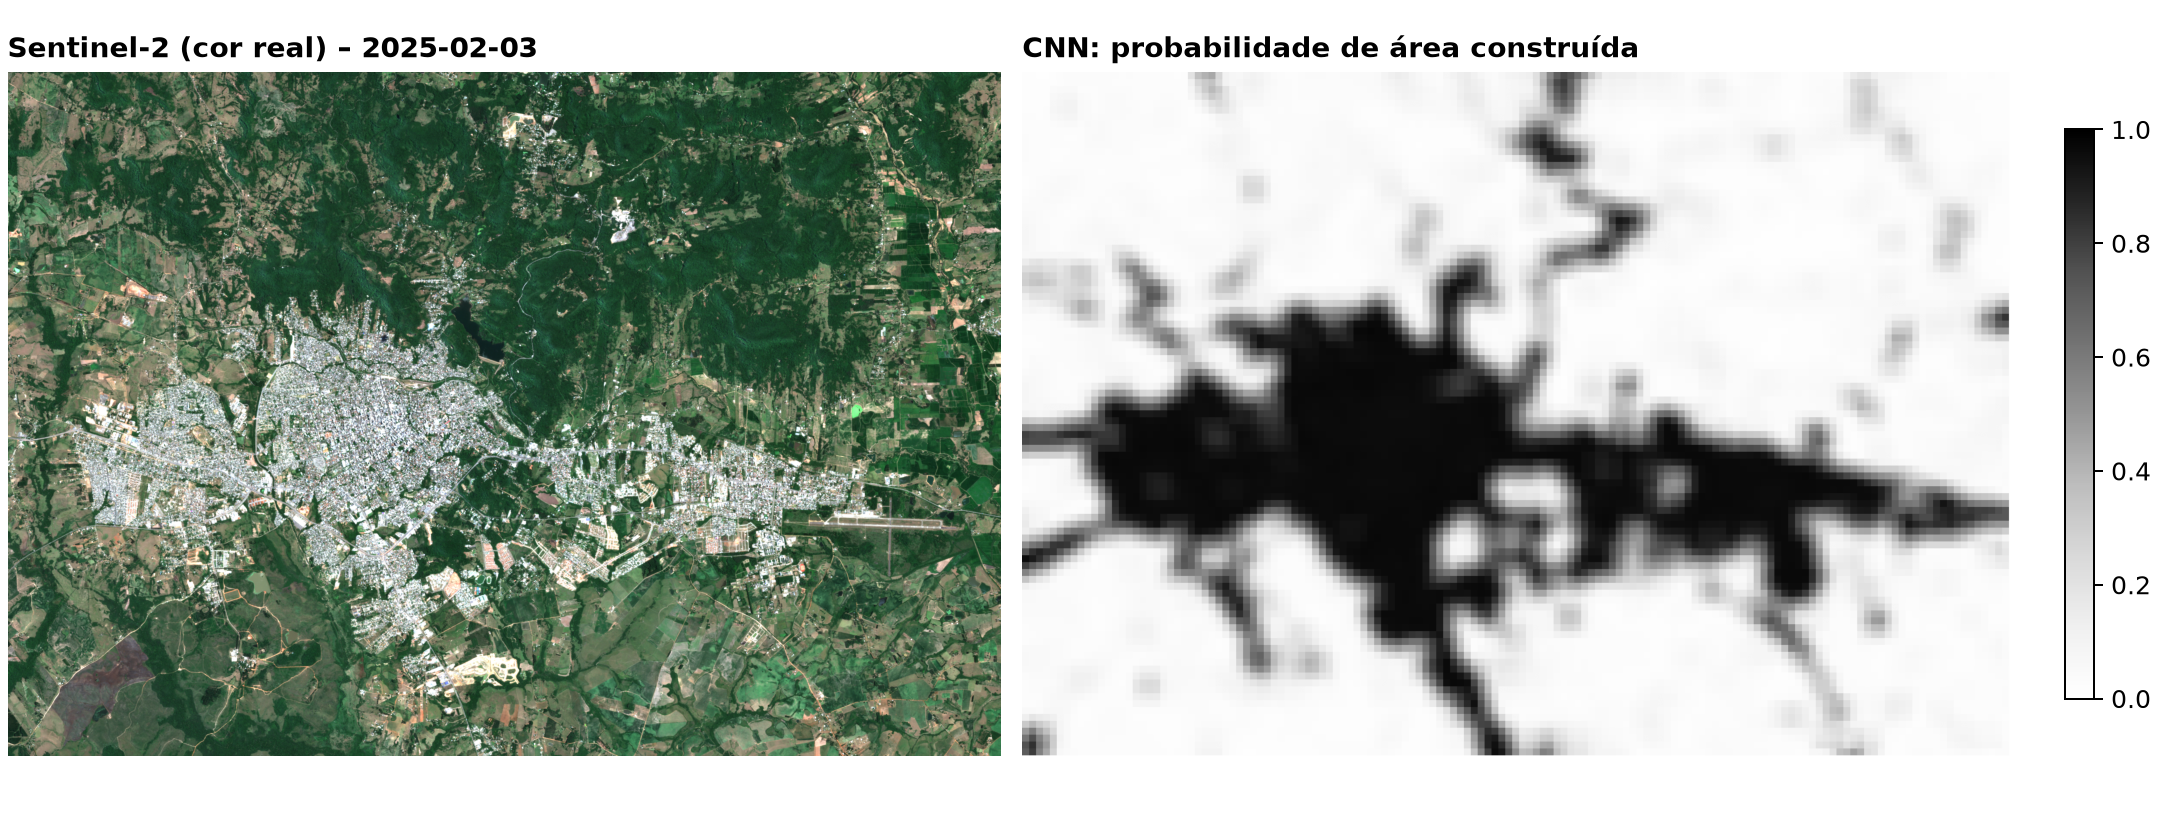

In [5]:
print(json.dumps(m_cnn["aplicacao_santa_maria"], indent=1, ensure_ascii=False))
Image(C.DOCS_IMG / "cnn_santa_maria.png")

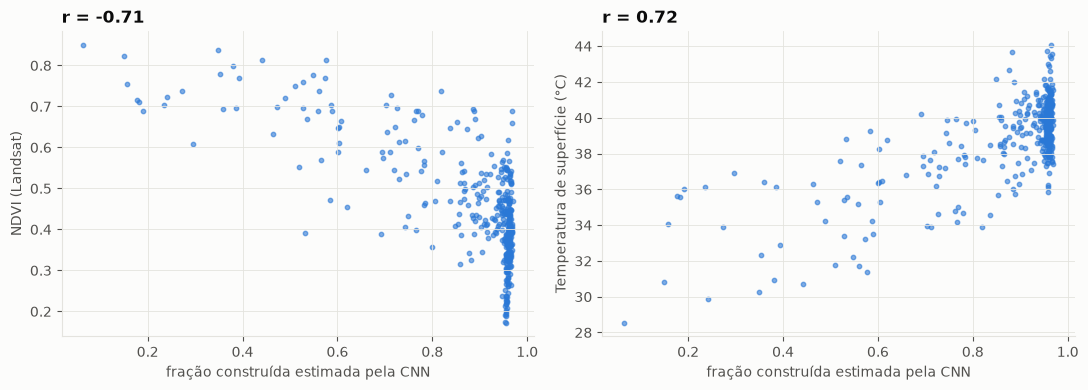

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, rot in zip(axs, ["ndvi_media", "lst_media"], ["NDVI (Landsat)", "Temperatura de superfície (°C)"]):
    ax.scatter(setores.frac_construida_cnn, setores[col], s=10, alpha=.6, color=figuras.AZUL)
    r = setores[["frac_construida_cnn", col]].corr().iloc[0, 1]
    ax.set_xlabel("fração construída estimada pela CNN"); ax.set_ylabel(rot); ax.set_title(f"r = {r:.2f}")
plt.tight_layout()

## 2. Índice de risco e perfis de setores

**Referencial:** risco climático do IPCC = **perigo × exposição × vulnerabilidade**, combinados por média geométrica: um setor sem idosos não pode ter risco alto, por mais quente que seja.

| Dimensão | Variáveis (normalizadas de 0 a 1) |
|---|---|
| Perigo | temperatura de superfície (70%), área construída da CNN (30%) |
| Exposição | número de idosos 60+ (60%), % de 70+ (40%) |
| Vulnerabilidade | pouca vegetação (40%), idosos não alfabetizados (30%), distância ao refúgio climatizado (30%) |

**K-Means:** o número de grupos foi escolhido pelo coeficiente de silhueta (k de 3 a 7).

In [7]:
display(pd.DataFrame(m_clu["avaliacao_k"]))
print("k escolhido:", m_clu["k_escolhido"], "| setores com valor do Censo imputado:", m_clu["setores_imputados"])
perfis = pd.read_csv(C.PROCESSED / "clusters_perfis.csv", index_col=0)
perfis[["perfil", "setores", "idosos", "indice_risco", "lst_media", "ndvi_media", "pct_idosos", "dist_refugio_km"]]

,k,silhueta,davies_bouldin,inercia
0,3,0.292,1.176,1395.710
1,4,0.289,1.297,1264.611
2,5,0.275,1.140,1142.524
3,6,0.214,1.210,1016.906
4,7,0.226,1.254,906.282


k escolhido: 3 | setores com valor do Censo imputado: 16


,perfil,setores,idosos,indice_risco,lst_media,ndvi_media,pct_idosos,dist_refugio_km
cluster,,,,,,,,
1,"Quente, envelhecido, pouco verde",201,28740.0,56.469,39.759,0.382,25.602,0.357
2,"Temperatura média, jovem, verde médio",146,15486.0,47.954,39.493,0.447,14.985,0.444
3,"Fresco, jovem, arborizado, longe de refúgio",59,4977.0,34.392,34.983,0.676,15.852,1.186


salvo docs/img/mapa_risco_refugios.png


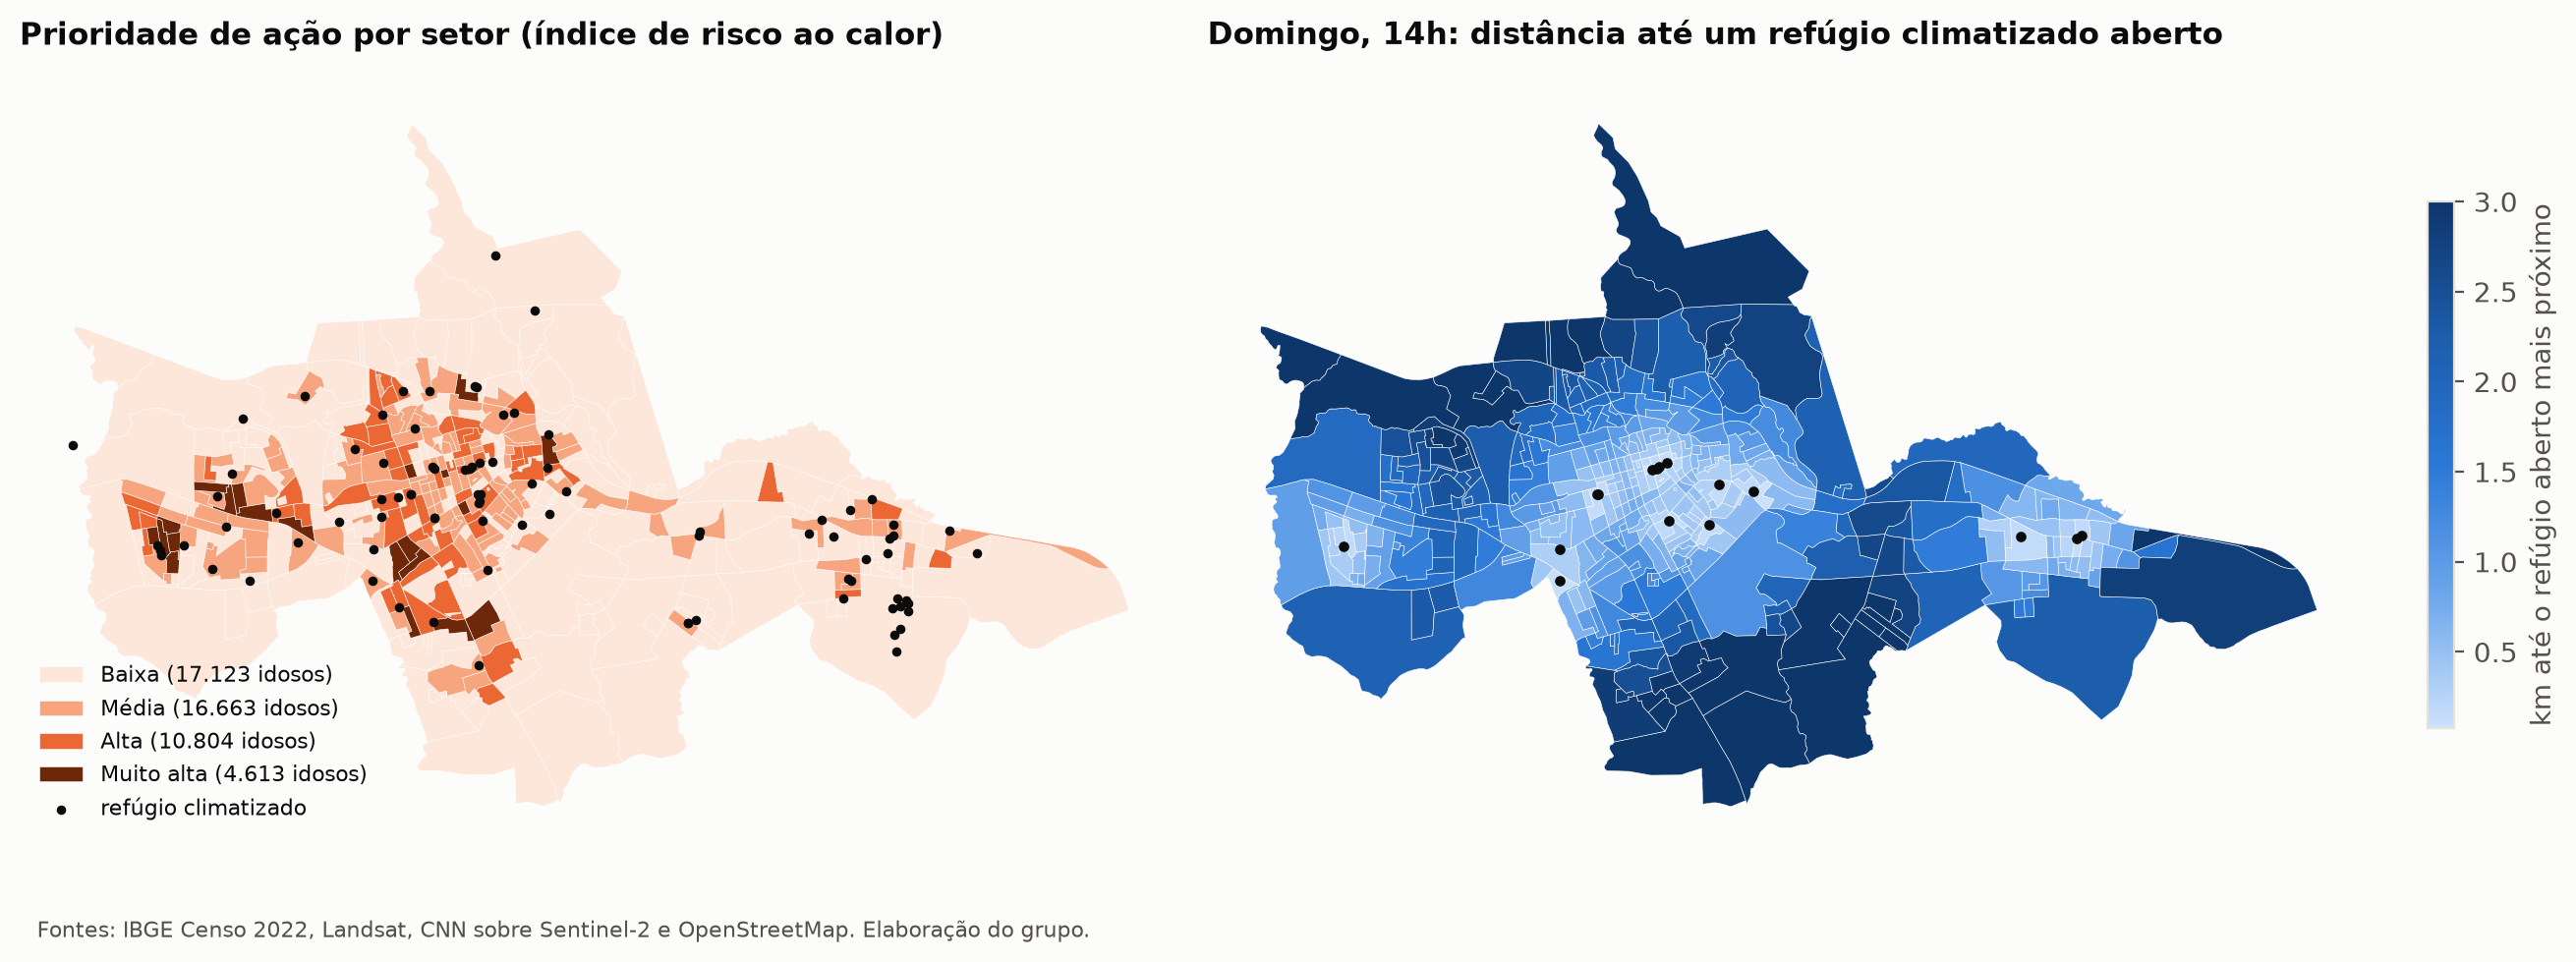

In [8]:
figuras.mapa_risco()
Image(C.DOCS_IMG / "mapa_risco_refugios.png")

In [9]:
cols = ["bairro", "indice_risco", "prioridade", "perfil_cluster", "lst_media", "idosos_60_mais", "ndvi_media", "dist_refugio_km"]
setores.sort_values("indice_risco", ascending=False)[cols].head(15)

,bairro,indice_risco,prioridade,perfil_cluster,lst_media,idosos_60_mais,ndvi_media,dist_refugio_km
324,Duque de Caxias,71.166,Muito alta,"Quente, envelhecido, pouco verde",41.062,231.0,0.340,0.772
337,Juscelino Kubitschek,70.743,Muito alta,"Quente, envelhecido, pouco verde",41.812,217.0,0.339,0.434
282,Dom Antônio Reis,70.166,Muito alta,"Quente, envelhecido, pouco verde",41.098,247.0,0.387,0.939
20,Centro,70.107,Muito alta,"Quente, envelhecido, pouco verde",38.919,281.0,0.261,0.323
25,Bonfim,69.541,Muito alta,"Quente, envelhecido, pouco verde",39.822,237.0,0.266,0.455
368,Tancredo Neves,68.619,Muito alta,"Quente, envelhecido, pouco verde",43.352,226.0,0.314,0.168
371,Tancredo Neves,68.215,Muito alta,"Quente, envelhecido, pouco verde",43.447,207.0,0.329,0.351
369,Tancredo Neves,68.090,Muito alta,"Quente, envelhecido, pouco verde",42.591,213.0,0.339,0.479
370,Tancredo Neves,67.443,Muito alta,"Quente, envelhecido, pouco verde",42.975,227.0,0.328,0.208
330,Duque de Caxias,67.412,Muito alta,"Quente, envelhecido, pouco verde",39.046,261.0,0.463,0.641


## 3. Recomendação

### 3.1 Refúgio climático para o cidadão (personalizada)
Pontuação = 0,45 × proximidade (decai com a distância que a pessoa consegue andar) + 0,35 × adequação à necessidade (climatizado, sombra ou atendimento) + 0,20 × frescor do entorno (temperatura de superfície no local). **Só entram locais abertos no dia e na hora.**

In [10]:
from src.ml.recomendacao import Perfil, recomendar_refugios
for nome, p in {
    "Dona Maria, 78, Tancredo Neves, quarta 14h, anda 500 m, precisa de ar-condicionado": Perfil(-29.6955, -53.8580, 2, 14, 500, "climatizado"),
    "Mesma pessoa, no DOMINGO": Perfil(-29.6955, -53.8580, 6, 14, 500, "climatizado"),
    "Seu João, 82, Centro, domingo 15h, anda 800 m": Perfil(-29.6847, -53.8069, 6, 15, 800, "climatizado"),
}.items():
    rec = recomendar_refugios(p)
    print(f"\n{nome}:")
    print("   (nenhum refúgio aberto ao alcance)" if rec.empty else "\n".join(f"   {i}. {e}" for i, e in enumerate(rec.explicacao, 1)))


Dona Maria, 78, Tancredo Neves, quarta 14h, anda 500 m, precisa de ar-condicionado:
   1. Unidade Básica de Saúde Parque (saude) a 0.3 km, climatizado, aberto até 17h
   2. Unidade Básica de Saúde Doutor Floriano Rocha (saude) a 0.7 km, climatizado, aberto até 17h
   3. Estratégia Saúde da Família Roberto Binato (saude) a 0.8 km, climatizado, aberto até 17h

Mesma pessoa, no DOMINGO:
   1. Praça dos Gêmeos (parque) a 0.3 km, ao ar livre com sombra, aberto até 20h
   2. Parque Residencial Lopes (parque) a 0.6 km, ao ar livre com sombra, aberto até 20h
   3. Praça Pedro Custódio Barboza (parque) a 0.5 km, ao ar livre com sombra, aberto até 20h

Seu João, 82, Centro, domingo 15h, anda 800 m:
   1. Shopping Independência (Camelódromo) (shopping) a 0.1 km, climatizado, aberto até 22h
   2. Galerias Roth (shopping) a 0.2 km, climatizado, aberto até 22h
   3. Santa Maria Shopping (shopping) a 0.3 km, climatizado, aberto até 22h


In [11]:
pd.DataFrame(m_rec["refugios"]).T.round(1)

,idosos_com_refugio_climatizado_aberto_ate_800m_%,idosos_com_refugio_climatizado_aberto_ate_1500m_%,distancia_media_ponderada_m,baseline_mais_proximo_inadequado_ou_fechado_%,refugios_climatizados_abertos
dia_util_14h,88.7,97.9,461.5,49.7,87.0
domingo_14h,45.1,66.5,1226.0,93.2,16.0


**Leitura:** num dia útil, a grande maioria dos idosos tem um refúgio climatizado aberto a uma caminhada curta. **No domingo essa cobertura cai muito**, porque as unidades de saúde, os CRAS e as bibliotecas fecham. O baseline ingênuo ("o ponto mais próximo") mandaria a maioria das pessoas para um local fechado ou inadequado. **Recomendação ao poder público:** abrir pelo menos uma unidade por região nos domingos de onda de calor.

### 3.2 Prioridade de plantio de árvores (gestor)

In [12]:
p = m_rec["plantio"]
print(f"Relação observada: cada +0,1 de NDVI -> {p['resfriamento_por_0_1_ndvi_C']:.2f} °C a menos na superfície (R² = {p['r2']:.2f})")
cap = pd.Series(p["beneficio_capturado_top_k"]).sort_values(ascending=False)
display(cap.rename(f"benefício (idoso·°C) dos {p['top_k']} primeiros setores").to_frame())
print(f"Estabilidade do ranking (Kendall tau ao variar premissas): mínimo {p['kendall_tau_estabilidade_min']:.2f}, média {p['kendall_tau_estabilidade_media']:.2f}")
display(pd.read_csv(C.PROCESSED / "plantio_por_bairro.csv").head(10))

Relação observada: cada +0,1 de NDVI -> 1.33 °C a menos na superfície (R² = 0.61)


,benefício (idoso·°C) dos 20 primeiros setores
recomendador_plantio,6338.786
mais_idosos,4993.332
mais_quentes,4279.842
menos_verdes,2830.218
aleatorio_media_100x,2129.821


Estabilidade do ranking (Kendall tau ao variar premissas): mínimo 0.64, média 0.80


,bairro,beneficio,idosos,lst,ndvi
0,Centro,5754.010,4422.0,39.315,0.287
1,Camobi,4124.194,4434.0,39.496,0.451
2,Juscelino Kubitschek,2846.653,2604.0,40.761,0.413
3,Nossa Senhora de Fátima,2616.491,1971.0,39.419,0.351
4,Tancredo Neves,2547.514,2291.0,42.090,0.396
5,Bonfim,2080.184,1567.0,39.825,0.297
6,Nossa Senhora Medianeira,1970.883,1795.0,39.511,0.399
7,Nossa Senhora do Rosário,1784.082,1405.0,39.987,0.365
8,Salgado Filho,1753.865,1524.0,40.851,0.417
9,Pinheiro Machado,1704.022,1973.0,40.120,0.441


## 4. Limitações

- **Diferença de domínio na CNN:** o EuroSAT é europeu, e Santa Maria tem outros materiais e outra vegetação. Mitigamos ajustando a distribuição de cores e validando contra NDVI e temperatura, mas a CNN não foi validada com rótulos locais.
- **Índice de risco:** os pesos seguem a literatura, mas são uma escolha do grupo. Por isso mostramos a estabilidade do ranking.
- **Refúgios:** a lista vem do OpenStreetMap, e a climatização e o horário são premissas por categoria. Em produção, a Prefeitura confirmaria cada local.
- **Plantio:** a relação NDVI × temperatura é observacional (correlação, não causalidade) e vale para a superfície, não para o ar.